 SEVENTEEN EIGHTEEN
torch.Size([1, 80, 167])


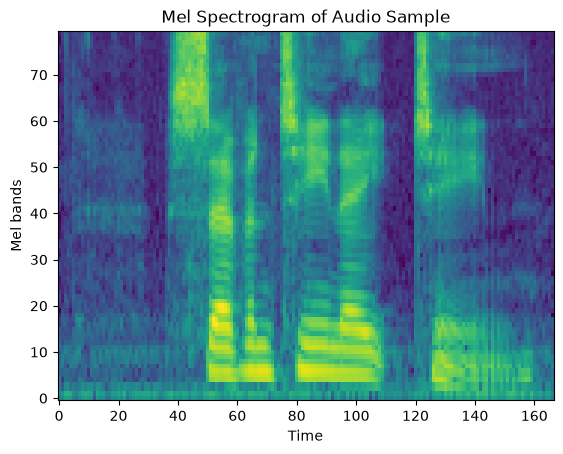

In [ ]:
from pathlib import Path
import torchaudio
from torchaudio.transforms import MelSpectrogram, AmplitudeToDB
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

# A signal needs to be sampled at a rate $f_s \geq 2 f_{max}$ in order to avoid distortions.
# Since most phonetic information lies below 8 Hz, a common sample rate for speech is 16 kHz.
# Larger STFT windows increase frequency resolution but lower temporal resolution. In other
# words, a larger STFT window allows for more fine grained frequency bins, but each frame will
# cover a larger time frame, blurring rapid changes. The opposite is also true. Given this
# tradeoff, a common window size is 25 ms. The x-axis of a MEL spectrogram represents time
# while its y-axis displays MEL bands. Each band groups frequencies that scale linearly
# beneath 1000 Hz and logarithmically above, matching how the human ear perceives sound.
def plot_spectrogram(spectrogram):
  _, ax = plt.subplots(1, 1)
  ax.set_title("Mel Spectrogram of Audio Sample")
  ax.set_ylabel("Mel bands")
  ax.set_xlabel("Time")
  ax.imshow(spectrogram.permute(1, 2, 0), origin="lower", aspect="auto", interpolation="nearest")

class LibriSpeech(Dataset):
  def __init__(self, base_path, set_type):
    self.mel_transform = MelSpectrogram(sample_rate=16000, n_fft=400, n_mels=80)
    self.db_transform = AmplitudeToDB("power", 80.0)

    self.root_dir = Path(f"{base_path}/{set_type}")
    files = [p for p in self.root_dir.rglob("*") if p.is_file() and not p.name.endswith(".txt")]
    self.audio_paths = list(sorted(files))
    self.transcript_cache = {}

  def get_transcript(self, audio_path):
    name, _ = audio_path.name.split(".")
    s, c, i = name.split("-")[-3:]
    transcript_path = f"{self.root_dir}/{s}/{c}/{s}-{c}.trans.txt"

    if transcript_path in self.transcript_cache:
      lines = self.transcript_cache[transcript_path]
      return lines[int(i)][len(name):]

    with open(transcript_path, "r") as file:
      lines = file.read().split("\n")
      self.transcript_cache[transcript_path] = lines
      return lines[int(i)][len(name):]

  def __len__(self):
    return len(self.audio_paths)

  def __getitem__(self, idx):
    waveform, sample_rate = torchaudio.load(self.audio_paths[idx])
    assert sample_rate == 16000 # As desribed by the dataset
    spectrogram = self.db_transform(self.mel_transform(waveform))
    transcript = self.get_transcript(self.audio_paths[idx])
    return spectrogram, transcript

dataset = LibriSpeech(".cache/LibriSpeech", "dev-clean")
loader = DataLoader(dataset, shuffle=True, batch_size=1)

samples, labels = next(iter(loader))
print(labels[0])
plot_spectrogram(samples[0])
print(samples[0].shape)

TODO:
- Understand SpecAugment:
  - Time masking: mask out a random vertical strip from [x, x + k]
  - Frequency masking: mask out a random horizontal strip from [y, x + l]
  - sparse_image_warp:
    - Flows for control points are `destination_points - source_points` and flows for boundary points at initialized to 0
    - Interpolate the control points using a polyharmonic spline
      - **TODO: need to better understand how to compute polyharmonic splines**
    - `img[y, x] = img[y - flow[y, x], x]`, and since flows are floats, bilinearly interpolate the 4 neighboring pixels to the target pixel
- Process audio samples in chunks, since track length is variable
- Load model weights for nvidia's parkeet model
- First run a demo to visualize the mel spectrogram for each sample chunk


https://github.com/tensorflow/addons/blob/master/tensorflow_addons/image/sparse_image_warp.py#L23
https://github.com/tensorflow/addons/blob/master/tensorflow_addons/image/dense_image_warp.py#L183
https://github.com/tensorflow/addons/blob/master/tensorflow_addons/image/interpolate_spline.py#L237
https://mathsfromnothing.au/polyharmonic-spline/
https://en.wikipedia.org/wiki/Polyharmonic_spline